# Prompt to decision tree

Paste an evaluator prompt and get an interactive HTML report:

- the **decision tree** (entry inputs to decision diamonds to verdict leaves),
- the **issues** that make it inconsistent (gray zones, contradictions, redundancies, missing tie-breaks, ambiguous scope),
- the **prompt highlighted** by owning node, linked to a **movable** graph, with a legend.

Three model calls do the reasoning: extract the tree, reorder it for correct precedence, find issues.

## 1. Install

In [4]:
!pip install --quiet openai

## 2. Your Nebius API key

In [5]:
from dotenv import load_dotenv
import os

load_dotenv()
API_KEY = os.environ["NEBIUS_API_KEY"]

## 3. Start the model client

In [6]:
from openai import OpenAI

client = OpenAI(base_url="https://api.tokenfactory.nebius.com/v1/", api_key=API_KEY)
MODEL = "meta-llama/Llama-3.3-70B-Instruct"

def chat(system, user, temperature=0.2, max_tokens=4000):
    r = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
        temperature=temperature, max_tokens=max_tokens)
    return r.choices[0].message.content.strip()

print("Ready ->", chat("Reply with one word.", "say: ok", max_tokens=10))

Ready -> ok


## 4. Write the prompt to analyse
Edit this, or paste your own evaluator/judge prompt.

In [7]:
PROMPT =  """
You are a fact-checking judge. You will be given a CONTEXT and an ANSWER.
Your job is to decide whether the ANSWER is grounded in the CONTEXT.

Rules:
accordiung to priority:
- "good": every factual

 claim in the ANSWER is directly supported or logically entailed by the CONTEXT.
- Ignore style, grammar, and opinions — only judge factual grounding.
- Do not use outside knowledge; judge solely based on the CONTEXT provided.
- Negative claims: if the ANSWER says something was NOT included or did NOT happen, and the CONTEXT providese enumeration or description that omits it, treat that absence as support — mark "good".
- "bad": the ANSWER contains at least one claim that contradicts the CONTEXT or not based on facts in the context.
- Absolute claims: words like "first", "only", "always", "never" require the CONTEXT to explicitly state them. Do not infer an absolute from partial evidence (e.g. the earliest item mentioned is not necessarily the first ever).

Reply with ONLY a JSON object, nothing else, in this exact format:
  {"reason": "<one sentence naming the fact that is or isn't supported>",
  "answer": "good" or "bad"}
""".strip()
print(len(PROMPT), "chars")

1137 chars


## 5. The three prompts
`TREE_SYS` extracts the tree, `ORDER_SYS` fixes evaluation order (overrides first, default last), `ISSUE_SYS` finds what hurts consistency. Each anchors to a verbatim quote.

In [8]:
SHAPE_SPEC = 'NODE KINDS (the only allowed vocabulary - pick the one that fits):\n- entry    : an input the judge receives ({input}, {context}, {output}, a text chunk).\n- decision : a branching QUESTION the judge answers to choose a path. Has >=2 outgoing edges.\n- subtask  : a deterministic transform before a decision (e.g. split into clauses, extract claims).\n- rule     : a tie-break / override / constraint that bends a decision.\n- verdict  : a terminal output label the judge emits (fact / not_fact / grounded / score=3). No outgoing edges.\n- side_note: a statement NOT part of the decision flow (persona, framing, formatting boilerplate, an aside).\n\nHARD RULES:\n1. The tree flows top-down: entry inputs -> decision diamonds (out-edges labelled with the branch condition) -> verdict leaves. Reads like "if X -> ask Y -> emit Z".\n2. NO background node in the flow. Persona/role/motivation/generic framing are side_note, never decisions.\n3. Every decision\'s outgoing edges are MUTUALLY EXCLUSIVE and together EXHAUSTIVE; label each edge with the condition that selects it.\n4. Anything that does not change the verdict becomes a side_note.\n5. Anchor each node: put the verbatim trigger phrase from the prompt in source_quote (<=160 chars, copied exactly). If you cannot quote it, you are inventing - do not.\n6. Labels are TERSE (<=6 words), clear and to the point. The detail lives in source_quote, not the label.'

TREE_SYS = 'You convert an LLM evaluator/judge prompt into a DECISION TREE.\n\nNODE KINDS (the only allowed vocabulary - pick the one that fits):\n- entry    : an input the judge receives ({input}, {context}, {output}, a text chunk).\n- decision : a branching QUESTION the judge answers to choose a path. Has >=2 outgoing edges.\n- subtask  : a deterministic transform before a decision (e.g. split into clauses, extract claims).\n- rule     : a tie-break / override / constraint that bends a decision.\n- verdict  : a terminal output label the judge emits (fact / not_fact / grounded / score=3). No outgoing edges.\n- side_note: a statement NOT part of the decision flow (persona, framing, formatting boilerplate, an aside).\n\nHARD RULES:\n1. The tree flows top-down: entry inputs -> decision diamonds (out-edges labelled with the branch condition) -> verdict leaves. Reads like "if X -> ask Y -> emit Z".\n2. NO background node in the flow. Persona/role/motivation/generic framing are side_note, never decisions.\n3. Every decision\'s outgoing edges are MUTUALLY EXCLUSIVE and together EXHAUSTIVE; label each edge with the condition that selects it.\n4. Anything that does not change the verdict becomes a side_note.\n5. Anchor each node: put the verbatim trigger phrase from the prompt in source_quote (<=160 chars, copied exactly). If you cannot quote it, you are inventing - do not.\n6. Labels are TERSE (<=6 words), clear and to the point. The detail lives in source_quote, not the label.\n\nReturn ONLY a JSON object with this exact shape:\n{\n  "title": "short name for the judge this prompt implements",\n  "root_id": "id of the entry node the flow starts at",\n  "nodes": [{"id": "snake_case", "kind": "entry|decision|subtask|rule|verdict|side_note", "label": "<=6 words", "source_quote": "verbatim phrase from the prompt"}],\n  "edges": [{"source": "id", "target": "id", "branch_label": "condition that selects this edge, or empty string"}]\n}\nExtract the tree HONESTLY as the prompt actually behaves; do not normalise toward what it "should" do.'

ORDER_SYS = 'You are given a judge prompt and a DRAFT decision tree extracted from it. Restructure the\ntree so the ORDER of evaluation is correct and it reads cleanly, WITHOUT changing what the prompt means.\n\nNODE KINDS (the only allowed vocabulary - pick the one that fits):\n- entry    : an input the judge receives ({input}, {context}, {output}, a text chunk).\n- decision : a branching QUESTION the judge answers to choose a path. Has >=2 outgoing edges.\n- subtask  : a deterministic transform before a decision (e.g. split into clauses, extract claims).\n- rule     : a tie-break / override / constraint that bends a decision.\n- verdict  : a terminal output label the judge emits (fact / not_fact / grounded / score=3). No outgoing edges.\n- side_note: a statement NOT part of the decision flow (persona, framing, formatting boilerplate, an aside).\n\nHARD RULES:\n1. The tree flows top-down: entry inputs -> decision diamonds (out-edges labelled with the branch condition) -> verdict leaves. Reads like "if X -> ask Y -> emit Z".\n2. NO background node in the flow. Persona/role/motivation/generic framing are side_note, never decisions.\n3. Every decision\'s outgoing edges are MUTUALLY EXCLUSIVE and together EXHAUSTIVE; label each edge with the condition that selects it.\n4. Anything that does not change the verdict becomes a side_note.\n5. Anchor each node: put the verbatim trigger phrase from the prompt in source_quote (<=160 chars, copied exactly). If you cannot quote it, you are inventing - do not.\n6. Labels are TERSE (<=6 words), clear and to the point. The detail lives in source_quote, not the label.\n\nFIX THESE STRUCTURAL PROBLEMS:\n1. PRECEDENCE. Override / tie-break / default rules ("when in doubt output X", "an A that contains B counts as B")\n   must sit where the judge actually applies them. A rule that FORCES a verdict belongs at its precedence point:\n   short-circuit overrides come BEFORE the decision they override; the catch-all default comes LAST.\n2. NO FAKE FUNNELS. If several nodes each independently route to the SAME verdict, do NOT chain them as a fake\n   branching path - we already know where they go. Make each a `rule` gate (yes -> the forced verdict, no -> next\n   check), placed in precedence order, or merge ones that share a precedence slot. Never bury an override below the\n   decision it is meant to override.\n3. READ TOP-DOWN in evaluation order: highest-precedence overrides first, then the main classification decision(s),\n   then the default fallback verdict.\n4. PRESERVE MEANING. Keep every node\'s verbatim source_quote. Do not invent or drop logic; only reorder, reattach,\n   or merge genuinely redundant nodes. Keep labels terse (<=6 words). Every decision/rule still has mutually\n   exclusive, exhaustive, labelled out-edges; every verdict stays terminal.\n\nReturn the restructured tree in the SAME JSON shape (title, root_id, nodes, edges).'

ISSUE_SYS = 'You audit an LLM evaluator/judge prompt for what makes it INCONSISTENT, given its decision tree.\n\nISSUE TYPES (use only these):\n- gray_zone        : a decision point with no tie-break rule - the model can reasonably go either way.\n- contradiction    : two branches/rules that can both fire and point to different verdicts.\n- redundancy       : overlapping or duplicated decisions that could be merged.\n- missing_tie_break: a concrete rule that, if added, would make a decision deterministic.\n- ambiguous_scope  : vague or underspecified wording (an undefined term, an open-ended list).\n\nReturn ONLY a JSON object:\n{\n  "issues": [{\n    "type": "gray_zone|contradiction|redundancy|missing_tie_break|ambiguous_scope",\n    "severity": "high|medium|low",\n    "title": "<=6 words naming the problem (e.g. \'neutral sentiment has no branch\')",\n    "node_ids": ["ids from the tree this concerns"],\n    "quote": "verbatim phrase from the prompt where the issue sits, copied exactly",\n    "explanation": "<=20 words: why this makes the judge inconsistent"\n  }]\n}\nKeep title and explanation SHORT; quote must be copied verbatim. Order by severity (high first). Return at most\n5 issues - only the ones that actually hurt consistency. If the prompt is genuinely clean, return an empty list.'

## 6. Run the pipeline
Three model calls: extract -> reorder -> find issues. The JSON is parsed leniently (the model sometimes wraps it in prose or fences).

In [9]:
import json, re

def call_json(system, user):
    raw = chat(system, user, temperature=0.2, max_tokens=4000)
    s = re.sub(r"^```(?:json)?|```$", "", raw.strip()).strip()
    try:
        return json.loads(s)
    except Exception:
        m = re.search(r"[\{\[].*[\}\]]", s, re.S)
        if not m:
            raise ValueError("model did not return JSON:\n" + raw[:500])
        return json.loads(m.group(0))

def extract_tree(prompt_text):
    return call_json(TREE_SYS, f"PROMPT TO CONVERT:\n\n{prompt_text}")

def reorder_tree(prompt_text, tree):
    try:
        fixed = call_json(ORDER_SYS, f"PROMPT:\n\n{prompt_text}\n\nDRAFT TREE (JSON):\n\n{json.dumps(tree, indent=2)}")
        return fixed if fixed.get("nodes") else tree
    except Exception:
        return tree

def find_issues(prompt_text, tree):
    try:
        return call_json(ISSUE_SYS, f"PROMPT:\n\n{prompt_text}\n\nDECISION TREE (JSON):\n\n{json.dumps(tree, indent=2)}").get("issues", [])
    except Exception:
        return []

def analyze(prompt_text):
    tree = extract_tree(prompt_text)
    tree = reorder_tree(prompt_text, tree)
    issues = find_issues(prompt_text, tree)
    return {"title": tree.get("title", "Prompt analysis"), "prompt_text": prompt_text, "tree": tree, "issues": issues}

print("Analysing with", MODEL, "...")
result = analyze(PROMPT)
print(f"  {len(result['tree'].get('nodes', []))} nodes, {len(result['issues'])} issues")

Analysing with meta-llama/Llama-3.3-70B-Instruct ...
  8 nodes, 3 issues


## 7. Render the report
All rendering is plain Python (below) - it builds one self-contained HTML page with the linked prompt / tree / issues and a pan-zoom graph.

In [10]:
# @title
import html, re, urllib.request, pathlib as _pathlib

NODE_KINDS = [('entry', 'stadium', '#868e96'), ('decision', 'diamond', '#d39e00'), ('subtask', 'box', '#6f42c1'), ('rule', 'rectangle', '#0d6efd'), ('verdict', 'double circle', '#28a745'), ('side_note', 'dashed flag', '#adb5bd')]
NODE_COLOR = {k: c for k, _s, c in NODE_KINDS}
ISSUE_TYPES = [('gray_zone', '#fd7e14'), ('contradiction', '#dc3545'), ('redundancy', '#6f42c1'), ('missing_tie_break', '#0dcaf0'), ('ambiguous_scope', '#d63384')]
ISSUE_COLOR = dict(ISSUE_TYPES)
SEVERITY_COLOR = {'high': '#dc3545', 'medium': '#d39e00', 'low': '#868e96'}


def _locate(text: str, quote: str) -> tuple[int, int] | None:
    q = (quote or "").strip()
    if len(q) < 3:
        return None
    idx = text.find(q)
    if idx >= 0:
        return idx, idx + len(q)
    pattern = re.sub(r"\s+", r"\\s+", re.escape(re.sub(r"\s+", " ", q)))
    m = re.search(pattern, text)
    return (m.start(), m.end()) if m else None

def _line_owners(text: str, nodes: list[dict]) -> list[dict]:
    lines = text.split("\n")
    offsets, pos = [], 0
    for ln in lines:
        offsets.append((pos, pos + len(ln)))
        pos += len(ln) + 1
    owners: list[dict] = [{} for _ in lines]
    for n in nodes:
        loc = _locate(text, n.get("source_quote", ""))
        if not loc:
            continue
        s, e = loc
        info = (e - s, NODE_COLOR.get(n.get("kind"), "#adb5bd"), f"{n.get('id')}: {n.get('label', '')}")
        for i, (ls, le) in enumerate(offsets):
            if ls < e and s < le:
                owners[i][n.get("id")] = info
    i, m = 0, len(lines)
    while i < m:
        if not lines[i].strip():
            i += 1
            continue
        j = i
        while j < m and lines[j].strip():
            j += 1
        owned = [k for k in range(i, j) if owners[k]]
        for k in range(i, j):
            if owned and not owners[k]:
                nearest = min(owned, key=lambda o: (abs(o - k), 0 if o < k else 1))
                owners[k] = dict(owners[nearest])
        i = j
    return owners

def _highlight_prompt(text: str, nodes: list[dict]) -> str:
    lines = text.split("\n")
    owners = _line_owners(text, nodes)
    out = []
    for i, ln in enumerate(lines):
        nl = "\n" if i < len(lines) - 1 else ""
        own = owners[i]
        if not own or not ln.strip():
            out.append(html.escape(ln) + nl)
            continue
        _olen, color, title = min(own.values(), key=lambda v: v[0])
        data = html.escape(",".join(sorted(own)))
        out.append(f'<mark class="seg" data-nodes="{data}" style="background:{color}33" '
                   f'title="{html.escape(title)}">{html.escape(ln)}</mark>{nl}')
    return "".join(out)

def _esc_mermaid(s: str, limit: int = 60) -> str:
    s = re.sub(r"\s+", " ", str(s or "")).replace('"', "'")
    return re.sub(r"[\[\]{}()|<>]", " ", s).strip()[:limit]

def _node_line(node: dict) -> str:
    nid, label = node["id"], _esc_mermaid(node.get("label", ""))
    return {
        "entry": f'  {nid}(["{label}"]):::entry',
        "decision": f'  {nid}{{"{label}"}}:::decision',
        "subtask": f'  {nid}[["{label}"]]:::subtask',
        "rule": f'  {nid}["{label}"]:::rule',
        "verdict": f'  {nid}((("{label}"))):::verdict',
    }.get(node.get("kind"), f'  {nid}>"{label}"]:::side_note')

def _render_mermaid(tree: dict) -> str:
    nodes, edges = tree.get("nodes", []), tree.get("edges", [])
    flow = [n for n in nodes if n.get("kind") != "side_note"]
    side = [n for n in nodes if n.get("kind") == "side_note"]
    ids = {n["id"] for n in flow}
    lines = ["flowchart TD"] + [_node_line(n) for n in flow]
    for e in edges:
        if e["source"] not in ids or e["target"] not in ids:
            continue
        lbl = _esc_mermaid(e.get("branch_label", ""), 32)
        lines.append(f'  {e["source"]} -->|"{lbl}"| {e["target"]}' if lbl
                     else f'  {e["source"]} --> {e["target"]}')
    if side:
        lines.append('  subgraph SIDE ["Outside the decision flow"]')
        lines.append("    direction TB")
        lines += [_node_line(n) for n in side]
        lines.append("  end")
    for kind, color in NODE_COLOR.items():
        dash = ",stroke-dasharray:4 3" if kind == "side_note" else ""
        lines.append(f"  classDef {kind} fill:{color}22,stroke:{color},color:#212529{dash};")
    return "\n".join(lines)

def _issues_html(issues: list[dict]) -> str:
    if not issues:
        return '<p class="muted">No issues found.</p>'
    rows = []
    for it in issues:
        color = ISSUE_COLOR.get(it.get("type"), "#dc3545")
        sev = (it.get("severity") or "low").lower()
        nodes = html.escape(",".join(it.get("node_ids", []) or []))
        title = html.escape(it.get("title") or it.get("type", ""))
        quote = html.escape(it.get("quote") or "")
        expl = html.escape(it.get("explanation") or "")
        q_html = f'<div class="iquote">&ldquo;{quote}&rdquo;</div>' if quote else ""
        e_html = f'<div class="iexpl">{expl}</div>' if expl else ""
        rows.append(
            f'<li class="irow" data-nodes="{nodes}" data-sev="{sev}" title="{html.escape(it.get("type", ""))}">'
            f'<div class="ihead"><span class="dot" style="background:{color}"></span>'
            f'<b>{title}</b><span class="sev" style="background:{SEVERITY_COLOR.get(sev, "#868e96")}">{sev}</span></div>'
            f'{q_html}{e_html}</li>'
        )
    return f'<ul class="issues">{"".join(rows)}</ul>'

def _legend_html() -> str:
    def group(label, items):
        chips = "".join(f'<span class="leg"><b style="background:{c}"></b>{html.escape(name)}'
                        f'{f" <i>{html.escape(shape)}</i>" if shape else ""}</span>'
                        for name, shape, c in items)
        return f'<div class="legend"><span class="lgl">{label}</span>{chips}</div>'

    nodes = group("Nodes", NODE_KINDS)
    itypes = group("Issue types", [(k, "", c) for k, c in ISSUE_TYPES])
    sev = group("Severity", [(s, "", SEVERITY_COLOR[s]) for s in ("high", "medium", "low")])
    note = ('<span class="leg muted">number on a node = issues affecting it &middot; '
            'dashed node = has an issue</span>')
    return nodes + itypes + sev.replace("</div>", note + "</div>")


_STYLE = "\n  body { font: 15px/1.55 -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;\n    margin: 0; color: #212529; background: #f8f9fa; }\n  header { background: #fff; border-bottom: 1px solid #dee2e6; padding: 16px 24px; }\n  header h1 { margin: 0 0 4px; font-size: 20px; }\n  .hint { color: #868e96; font-size: 12.5px; margin: 0 0 10px; }\n  .legend { display: flex; flex-wrap: wrap; align-items: center; gap: 5px 14px; margin: 5px 0; font-size: 12.5px; }\n  .lgl { font-weight: 600; color: #495057; min-width: 78px; }\n  .legend b { display: inline-block; width: 12px; height: 12px; border-radius: 3px; margin-right: 5px;\n    vertical-align: -1px; }\n  .leg i { color: #adb5bd; font-style: normal; }\n  .layout { display: grid; grid-template-columns: minmax(300px, 40%) 1fr; gap: 18px;\n    padding: 16px 24px 60px; align-items: start; }\n  .pane { background: #fff; border: 1px solid #dee2e6; border-radius: 10px; min-width: 0; }\n  .pane > h2 { margin: 0; padding: 11px 16px; border-bottom: 1px solid #eef0f2; font-size: 12px;\n    text-transform: uppercase; letter-spacing: .04em; color: #868e96; }\n  .prompt-pane { position: sticky; top: 12px; max-height: calc(100vh - 24px); display: flex; flex-direction: column; }\n  .prompt-body { overflow: auto; padding: 13px 16px; white-space: pre-wrap; word-wrap: break-word;\n    font: 13px/1.7 ui-monospace, Menlo, monospace; }\n  .right { display: flex; flex-direction: column; gap: 18px; min-width: 0; }\n  .body { padding: 14px 16px; }\n\n  mark.seg { background: transparent; color: inherit; border-radius: 3px; padding: 0 1px; cursor: pointer; }\n  mark.seg:hover { outline: 2px solid #f59e0b; }\n  mark.seg.active { box-shadow: 0 0 0 2px rgba(245,158,11,.65); background: rgba(245,158,11,.30) !important; }\n\n  .graph-wrap { position: relative; height: 560px; overflow: hidden; background: #fff;\n    border-radius: 8px; cursor: grab; }\n  .graph-wrap.grabbing { cursor: grabbing; }\n  .graph-wrap .mermaid { position: absolute; top: 0; left: 0; transform-origin: 0 0; }\n  .graph-wrap .mermaid svg { max-width: none !important; }\n  .zoom-ctl { position: absolute; top: 8px; right: 8px; display: flex; gap: 4px; z-index: 5; }\n  .zoom-ctl button { height: 26px; min-width: 26px; padding: 0 7px; border: 1px solid #dee2e6; background: #fff;\n    border-radius: 6px; cursor: pointer; font-size: 13px; line-height: 1; color: #495057; }\n  .zoom-ctl button:hover { background: #f1f3f5; }\n  .mermaid g.node { cursor: pointer; }\n  .mermaid g.node.has-issue > :is(path, rect, polygon, circle, ellipse) {\n    stroke-dasharray: 5 3; stroke-width: 2px; }\n  .mermaid g.node.active > :is(path, rect, polygon, circle, ellipse) {\n    stroke: #f59e0b !important; stroke-width: 3px !important; stroke-dasharray: 0 !important; }\n  .issue-badge { paint-order: stroke; }\n\n  ul.issues { list-style: none; margin: 0; padding: 0; display: flex; flex-direction: column; gap: 6px; }\n  .irow { padding: 8px 10px; border-radius: 8px; cursor: pointer; border: 1px solid #eef0f2; }\n  .irow:hover, .irow.active { background: rgba(245,158,11,.12); border-color: rgba(245,158,11,.45); }\n  .ihead { display: flex; align-items: center; gap: 7px; font-size: 13.5px; }\n  .ihead b { font-weight: 600; }\n  .dot { flex: none; width: 9px; height: 9px; border-radius: 50%; }\n  .sev { margin-left: auto; font-size: 10px; color: #fff; padding: 1px 7px; border-radius: 9px;\n    text-transform: uppercase; letter-spacing: .03em; }\n  .iquote { font: 12px/1.5 ui-monospace, Menlo, monospace; color: #6c757d; margin: 5px 0 3px;\n    padding-left: 9px; border-left: 2px solid #e9ecef; }\n  .iexpl { font-size: 12.5px; color: #495057; }\n  .muted { color: #adb5bd; }\n  @media (max-width: 880px) { .layout { grid-template-columns: 1fr; }\n    .prompt-pane { position: static; max-height: none; } }\n"

# Script without CDN import — mermaid is inlined into the page by build_html
_SCRIPT = """
<script>
(async () => {
  mermaid.initialize({ startOnLoad: false, theme: 'neutral',
    flowchart: { curve: 'basis', nodeSpacing: 40, rankSpacing: 55 } });
  await mermaid.run({ querySelector: '.mermaid' });

  const nodeEl = {};
  document.querySelectorAll('.mermaid g.node').forEach(g => {
    const m = g.id.match(/flowchart-(.+)-\\d+$/);
    if (m) nodeEl[m[1]] = g;
  });
  const segMap = {}, issueMap = {};
  const index = (sel, store) => document.querySelectorAll(sel).forEach(el => {
    (el.dataset.nodes || '').split(',').filter(Boolean).forEach(id => {
      (store[id] = store[id] || []).push(el);
    });
  });
  index('mark.seg', segMap);
  index('.irow', issueMap);

  const SEV_RANK = { high: 3, medium: 2, low: 1 };
  const SEV_COL = { high: '#dc3545', medium: '#d39e00', low: '#868e96' };
  const byNode = {};
  document.querySelectorAll('.irow').forEach(r => {
    const sev = r.dataset.sev || 'low';
    (r.dataset.nodes || '').split(',').filter(Boolean).forEach(id => {
      const cur = byNode[id] || { count: 0, sev: 'low' };
      cur.count += 1;
      if (SEV_RANK[sev] > SEV_RANK[cur.sev]) cur.sev = sev;
      byNode[id] = cur;
    });
  });
  const NS = 'http://www.w3.org/2000/svg';
  Object.entries(byNode).forEach(([id, info]) => {
    const g = nodeEl[id];
    if (!g) return;
    g.classList.add('has-issue');
    const shape = g.querySelector('rect, polygon, circle, ellipse, path');
    if (!shape) return;
    const bb = shape.getBBox();
    const cx = bb.x + bb.width, cy = bb.y;
    const c = document.createElementNS(NS, 'circle');
    c.setAttribute('cx', cx); c.setAttribute('cy', cy); c.setAttribute('r', 9);
    c.setAttribute('fill', SEV_COL[info.sev]); c.setAttribute('stroke', '#fff');
    c.setAttribute('stroke-width', '1.5'); c.setAttribute('class', 'issue-badge');
    const t = document.createElementNS(NS, 'text');
    t.setAttribute('x', cx); t.setAttribute('y', cy + 0.5);
    t.setAttribute('text-anchor', 'middle'); t.setAttribute('dominant-baseline', 'central');
    t.setAttribute('fill', '#fff'); t.setAttribute('font-size', '11'); t.setAttribute('font-weight', '700');
    t.textContent = String(info.count);
    g.appendChild(c); g.appendChild(t);
  });

  let pinned = null;
  const clearAll = () => document.querySelectorAll('.active').forEach(e => e.classList.remove('active'));
  const paint = (ids) => ids.forEach(id => {
    if (nodeEl[id]) nodeEl[id].classList.add('active');
    (segMap[id] || []).forEach(e => e.classList.add('active'));
    (issueMap[id] || []).forEach(e => e.classList.add('active'));
  });
  const show = (ids) => { clearAll(); paint(ids); };
  const restore = () => { clearAll(); if (pinned) paint([pinned]); };
  const into = (el) => el && el.scrollIntoView({ block: 'center', inline: 'center', behavior: 'smooth' });
  const wire = (el, ids, counterpart) => {
    el.addEventListener('mouseenter', () => show(ids));
    el.addEventListener('mouseleave', restore);
    el.addEventListener('click', () => { pinned = ids[0]; show(ids); into(counterpart()); });
  };
  document.querySelectorAll('mark.seg').forEach(seg =>
    wire(seg, (seg.dataset.nodes || '').split(',').filter(Boolean), () => nodeEl[(seg.dataset.nodes || '').split(',')[0]]));
  document.querySelectorAll('.irow').forEach(row =>
    wire(row, (row.dataset.nodes || '').split(',').filter(Boolean), () => nodeEl[(row.dataset.nodes || '').split(',')[0]]));
  Object.entries(nodeEl).forEach(([id, g]) => wire(g, [id], () => (segMap[id] || [])[0]));

  const wrap = document.querySelector('.graph-wrap');
  const svg = wrap && wrap.querySelector('svg');
  if (svg) {
    let scale = 1, tx = 0, ty = 0, drag = false, ox = 0, oy = 0, startX = 0, startY = 0, moved = false;
    const apply = () => { svg.style.transform = `translate(${tx}px,${ty}px) scale(${scale})`; };
    const zoom = (factor, cx, cy) => {
      const ns = Math.min(4, Math.max(0.2, scale * factor));
      tx = cx - (cx - tx) * (ns / scale); ty = cy - (cy - ty) * (ns / scale); scale = ns; apply();
    };
    wrap.addEventListener('mousedown', e => {
      drag = true; moved = false; ox = tx; oy = ty; startX = e.clientX; startY = e.clientY;
      wrap.classList.add('grabbing');
    });
    window.addEventListener('mousemove', e => {
      if (!drag) return;
      const dx = e.clientX - startX, dy = e.clientY - startY;
      if (Math.abs(dx) + Math.abs(dy) > 4) moved = true;
      tx = ox + dx; ty = oy + dy; apply();
    });
    window.addEventListener('mouseup', () => { drag = false; wrap.classList.remove('grabbing'); });
    wrap.addEventListener('click', e => {
      if (moved && !e.target.closest('.zoom-ctl')) e.stopPropagation();
      moved = false;
    }, true);
    wrap.addEventListener('wheel', e => {
      e.preventDefault();
      const r = wrap.getBoundingClientRect();
      zoom(e.deltaY < 0 ? 1.1 : 1 / 1.1, e.clientX - r.left, e.clientY - r.top);
    }, { passive: false });
    const mid = () => { const r = wrap.getBoundingClientRect(); return [r.width / 2, r.height / 2]; };
    wrap.querySelector('.zin').onclick = () => zoom(1.2, ...mid());
    wrap.querySelector('.zout').onclick = () => zoom(1 / 1.2, ...mid());
    wrap.querySelector('.zreset').onclick = () => { scale = 1; tx = 0; ty = 0; apply(); };
  }
})();
</script>
"""

def _load_mermaid_js() -> str:
    cache = _pathlib.Path("_mermaid_cache.js")
    if not cache.exists():
        print("Downloading mermaid.js (once)...")
        urllib.request.urlretrieve(
            "https://cdn.jsdelivr.net/npm/mermaid@11/dist/mermaid.min.js", cache)
    return cache.read_text()


def build_html(result: dict) -> str:
    mermaid_js = _load_mermaid_js()
    title = result.get("title") or "Prompt analysis"
    tree = result.get("tree", {})
    issues = result.get("issues", []) or []
    prompt_html = _highlight_prompt(result.get("prompt_text", ""), tree.get("nodes", []))
    mermaid = html.escape(_render_mermaid(tree))

    head = (
        '<!doctype html><html lang="en"><head><meta charset="utf-8">'
        '<meta name="viewport" content="width=device-width, initial-scale=1">'
        f"<title>{html.escape(title)}</title>"
        f"<script>{mermaid_js}</script>"
        f"<style>{_STYLE}</style></head><body>"
    )
    body = f"""<header>
  <h1>{html.escape(title)}</h1>
  <p class="hint">Hover a prompt chunk, a tree node, or an issue &mdash; the matching ones light up. Drag the graph to move it, scroll to zoom.</p>
  {_legend_html()}
</header>
<div class="layout">
  <div class="pane prompt-pane">
    <h2>Source prompt</h2>
    <div class="prompt-body">{prompt_html}</div>
  </div>
  <div class="right">
    <div class="pane"><h2>Issues ({len(issues)})</h2>
      <div class="body">{_issues_html(issues)}</div></div>
    <div class="pane"><h2>Decision tree</h2>
      <div class="graph-wrap">
        <div class="zoom-ctl"><button class="zout" title="zoom out">&minus;</button>
          <button class="zreset" title="reset view">reset</button>
          <button class="zin" title="zoom in">+</button></div>
        <pre class="mermaid">{mermaid}</pre>
      </div></div>
  </div>
</div>"""
    return head + body + _SCRIPT + "</body></html>"


## 8. Show it
The report renders inline in an iframe. If Colab blocks the graph library, run the **download** cell below and open the HTML locally.

/Users/YOUR_USER/dev/cloud/nebius/Nebius_Eval_Deep_Dive_Talk mlops workshop/.venv/lib/python3.13/site-packages/IPython/core/display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



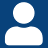
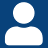
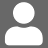

In [11]:
from IPython.display import HTML, display
import html as _html

doc = build_html(result)
with open("decision_tree.html", "w") as f:
    f.write(doc)
display(HTML(f'<iframe srcdoc="{_html.escape(doc)}" style="width:100%;height:860px;border:1px solid #dee2e6;border-radius:10px"></iframe>'))